In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def TASEP_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - xr_vec  #concentration of free ribosomes, separate pool for each


    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β']* xr_vec )
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec + 1/elong_fun(parameters['l'], parameters['lp'], xr_vec) * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec - parameters['γ'] * y_vec + 1/elong_fun(parameters['l'],parameters['lp'], xr_vec) * xr_vec)
    #reinitiation

    return new_x_vec, new_xr_vec, new_y_vec


def simulation_wrapper(state0, params, update,  elong_fun,sim_time, dt, record = [True, 100]): 
    
    states = np.zeros([int(sim_time/dt/record[1])+1, state0.shape[0], state0.shape[1]])
    next_t = state0
    
    for t in range(int(sim_time/dt)):
        
        if record[0]:
            if t % record[1] == 0:
                states[int(t/record[1])+1] = next_t
        next_t = update(params, next_t, dt, elong_fun)
    states[-1] = next_t
        
    return states[1:]

Redo a model without explicit competition but with ribosome loading dependent elongation rate (stiffness) to see whether the results from Fernandes et al (2017) can be qualitatively reproduced by a differential equation model

Keeping in mind that length-dependent intiation rates might be another way to go about this. 

Key assumtions: Ribosomes have individual pool, no protein resources e.g. aminoacids. 

In [3]:
#set parameters: 
rng = np.random.RandomState(seed = 5)
γ = 0.05
β = 0.01
α = 0.1
x_init = 1
sim_time = 100 #should be enough
dt = 0.001
N = 2
l = np.array([1,10])
Y = N*2
Rs = np.linspace(0.001,10,50)
Ys = 1 #1 for each, can see if this in any way infleunces the results (should do the total but not relative)

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

def β_lin(leng, n_trans):
    #negative slope relu
    le = leng * lin_scale
    no_rel = (- le * n_trans)+1
    return no_rel * (no_rel > 0.05) + 0.05 * (no_rel < 0.05)

def β_nonlin(leng, n_trans): 
    le = leng * nonlin_scale
    return  0.05 + 1/(1+ np.exp(-le * (-(n_trans))))

def R_fernandes(length, stiffness_mRNA, xr): 
    #might need to restrict to the 0 and 1 range... 
    return np.sqrt(2*length) * (xr + (1-xr)*stiffness_mRNA)**0.5

def stiffness_fun(length,k): 
    return length**(-k)

lin_scale = 5
nonlin_scale = 10

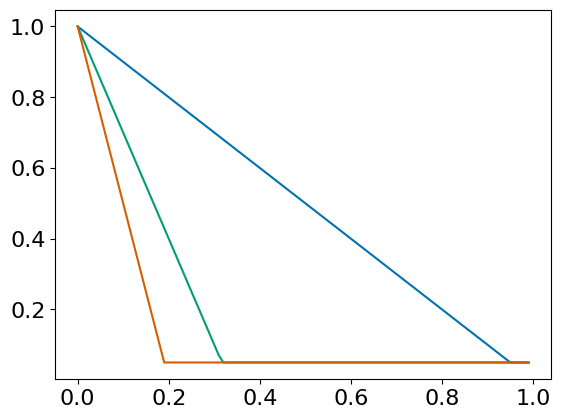

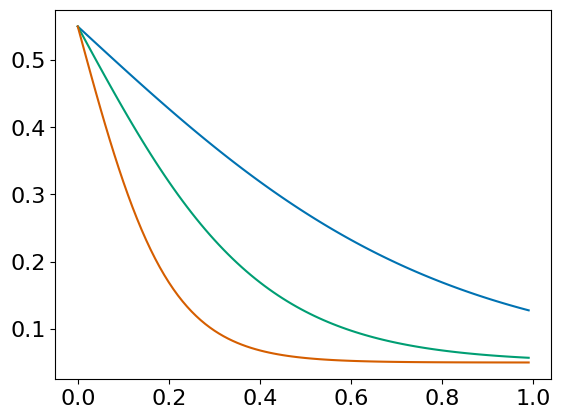

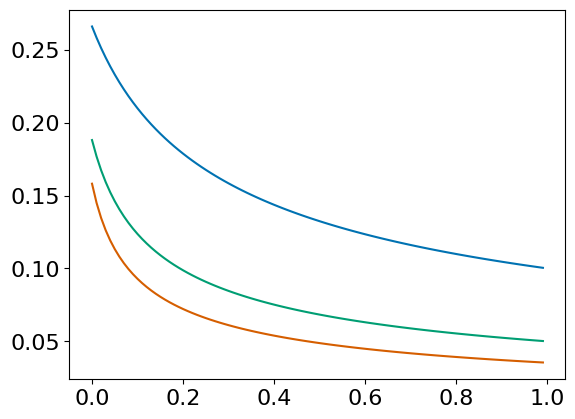

In [4]:
xrs = np.arange(0,1,0.01)
plt.plot(xrs, β_lin(0.2, xrs))
plt.plot(xrs, β_lin(0.6, xrs))
plt.plot(xrs, β_lin(1, xrs))
plt.show()

plt.plot(xrs, β_nonlin(0.25, xrs))
plt.plot(xrs, β_nonlin(.5, xrs))
plt.plot(xrs, β_nonlin(1, xrs))
plt.show()

p = 0.5
plt.plot(xrs, 1/R_fernandes(50, stiffness_fun(50,p), xrs))
plt.plot(xrs, 1/R_fernandes(200, stiffness_fun(200,p), xrs))
plt.plot(xrs, 1/R_fernandes(400, stiffness_fun(400,p), xrs))
plt.show()

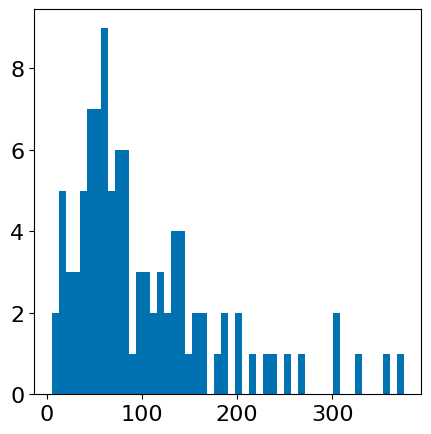

In [7]:
N = 100
Rs = np.linspace(0.01,200,num = 50)
mean, std = 2, 50
rng = np.random.RandomState(seed = 5)
l_samples = np.sort(rng.gamma(mean, std, N))

fig, ax = plt.subplots(1,1, figsize = (5,5))
ax.hist(l_samples, bins = 50)
plt.show()



#prepare the different groups for later analyses
b1 = np.nonzero(l_samples < 50)[0][-1]
b2 = np.nonzero(l_samples < 100)[0][-1]
b3 = np.nonzero(l_samples < 150)[0][-1]
b4 = np.nonzero(l_samples < 200)[0][-1]

s_1k = np.arange(0,b1+1,1, dtype = int)
s_2k = np.arange(b1+1,b2+1,1, dtype = int)
s_3k = np.arange(b2+1,b3+1,1, dtype = int)
s_4k = np.arange(b3+1,b4+1,1, dtype = int)
b_4k = np.arange(b4+1,N,1, dtype = int)



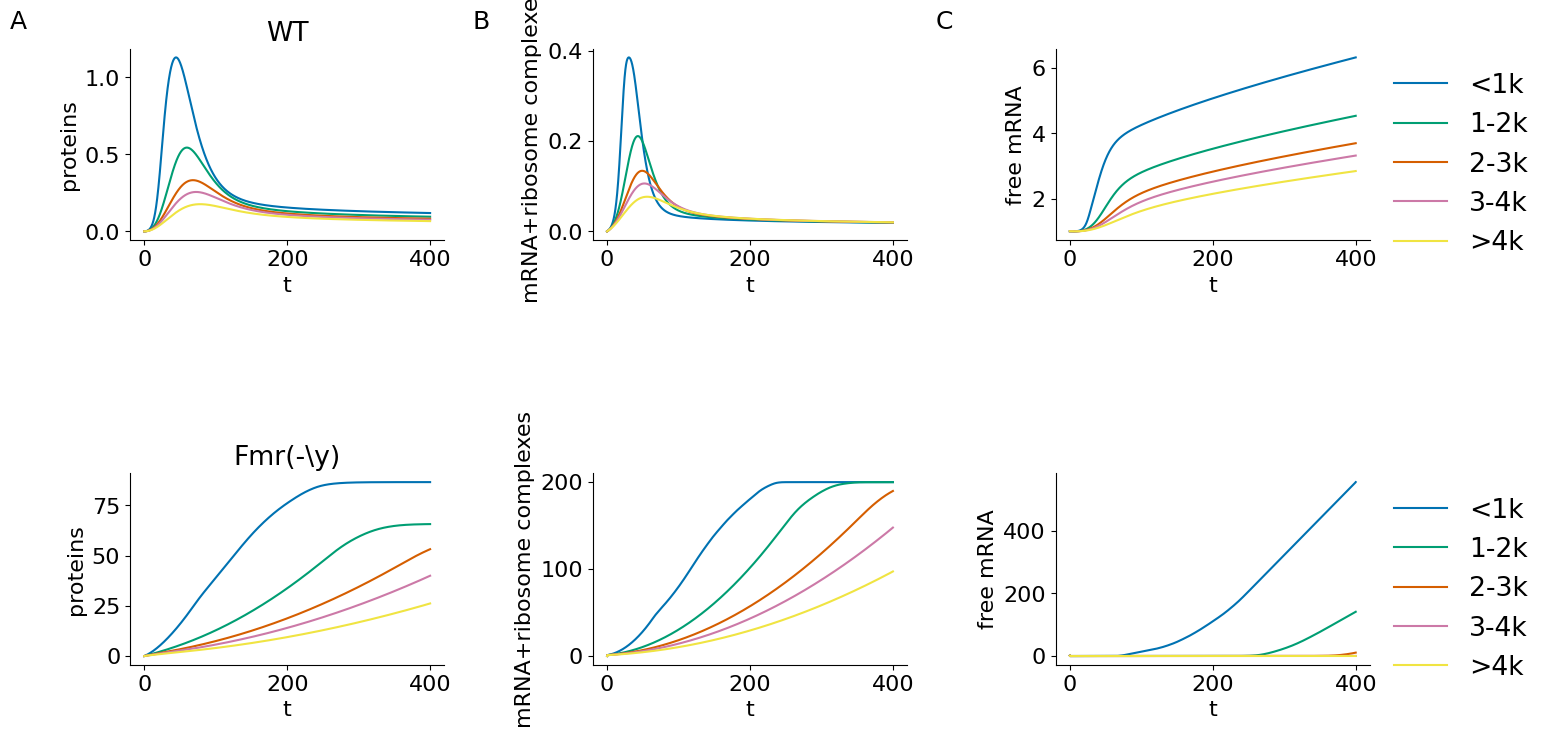

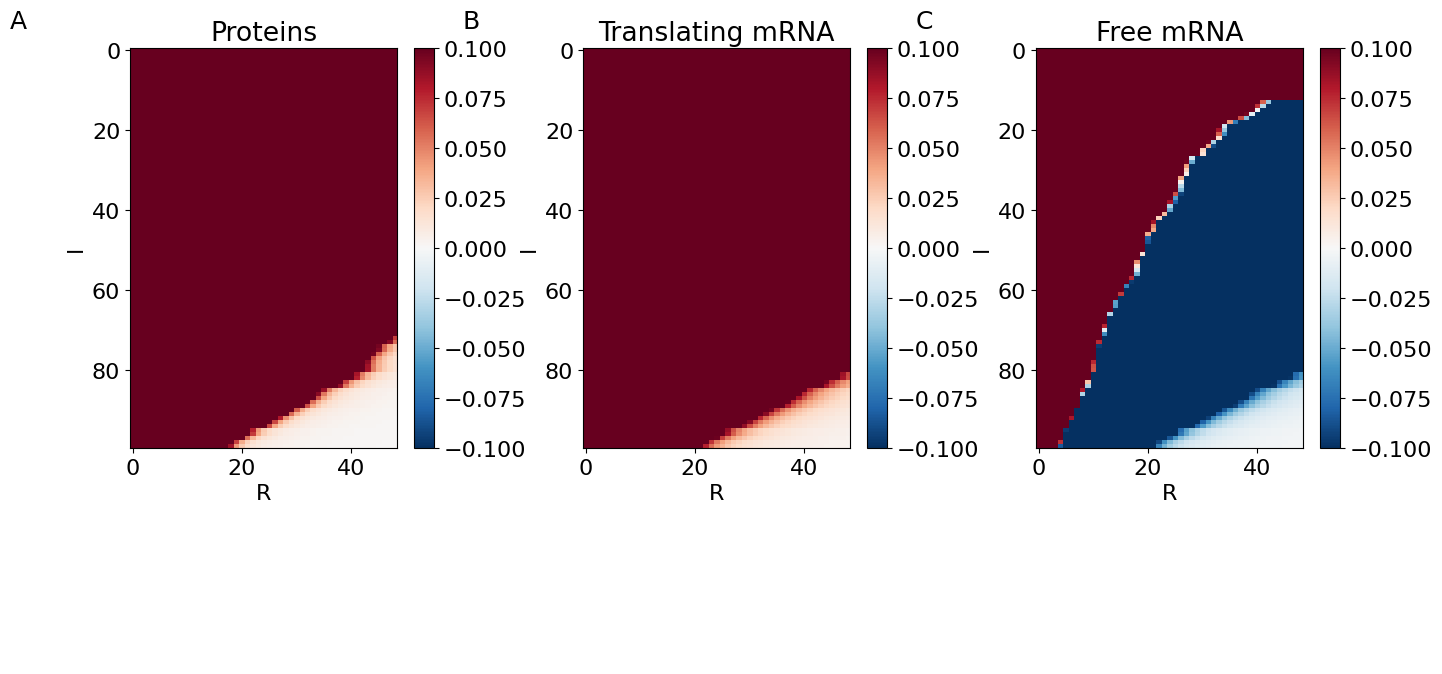

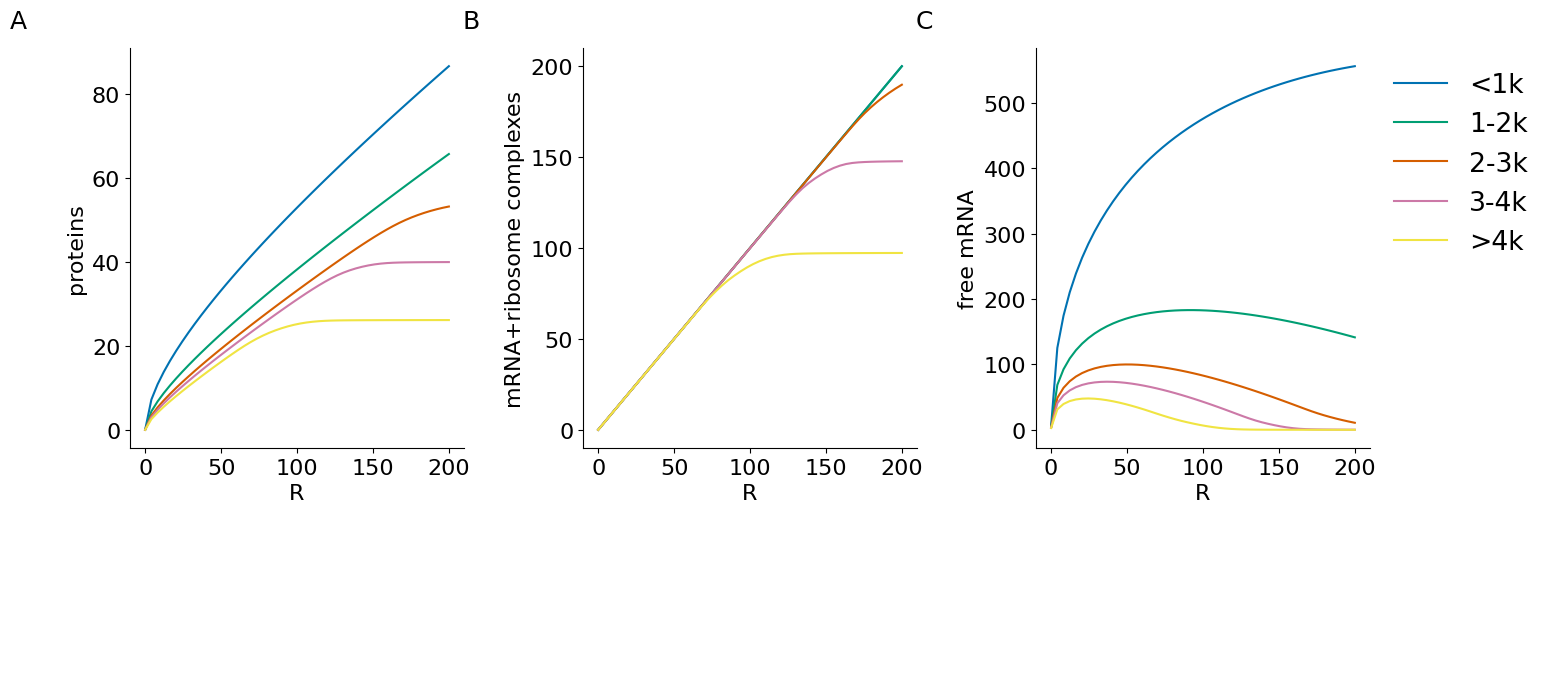

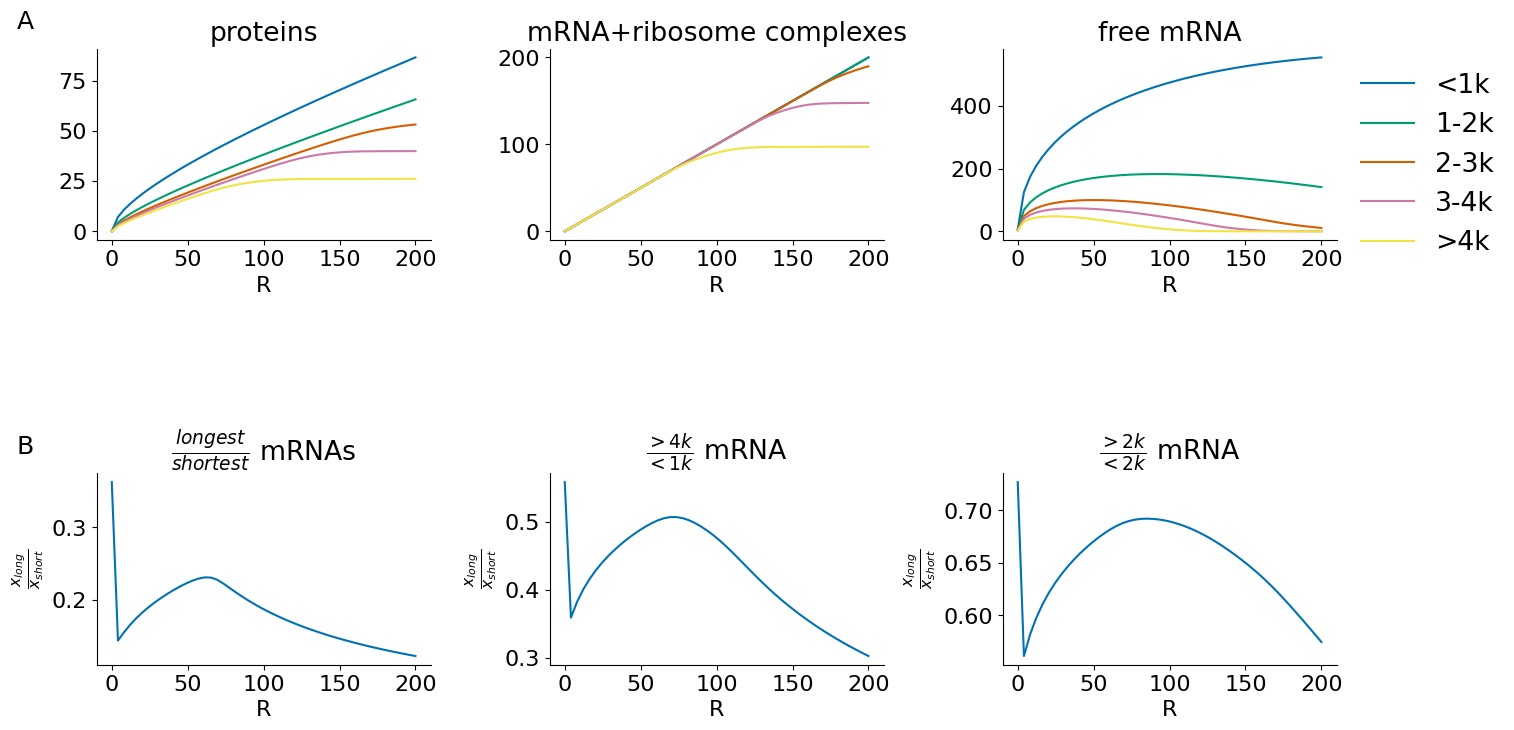

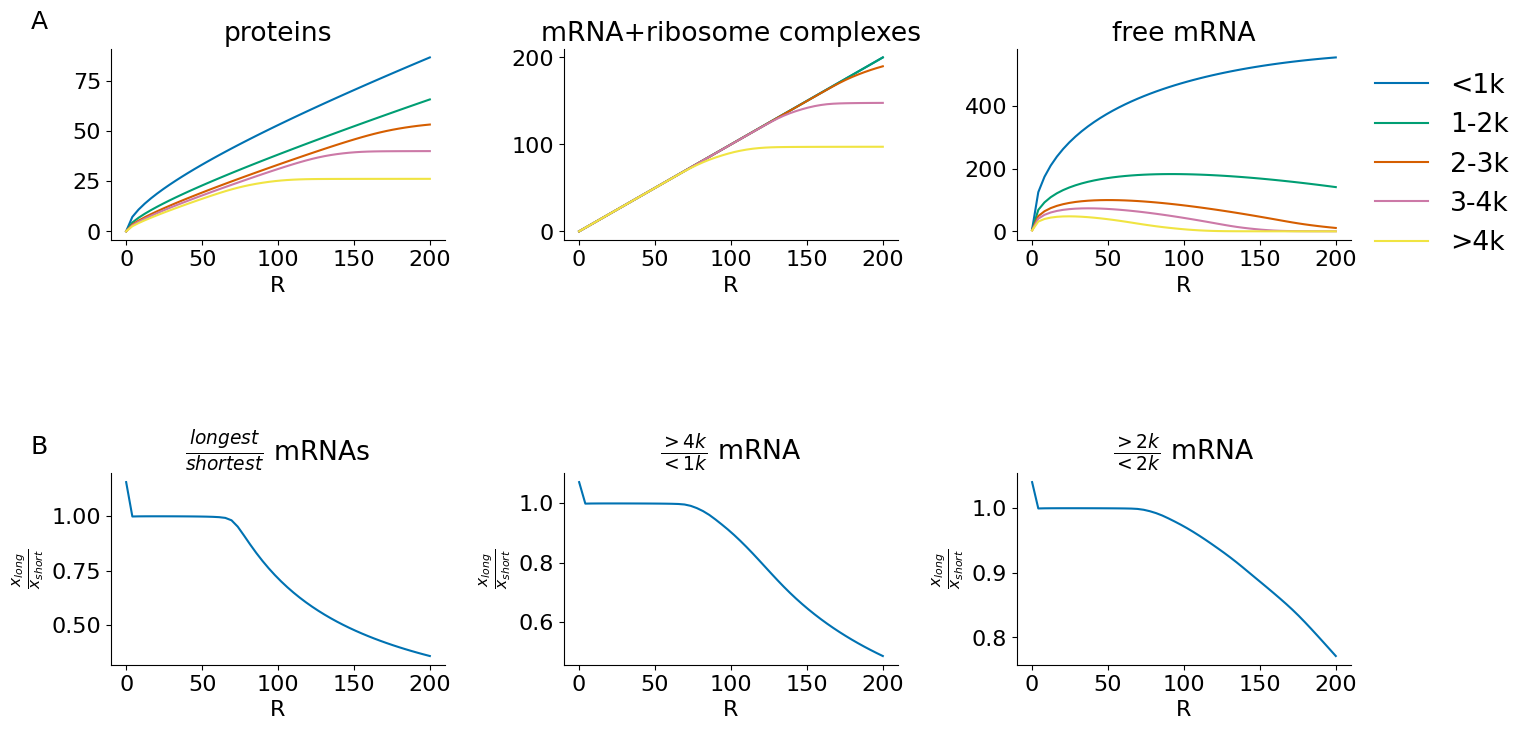

In [8]:
sim_time = 400 #this might be varied per simulation as we need to make sure all simulation reach their steady state
Y = N
sampling = 100
results_lp = np.zeros([Rs.shape[0], int(sim_time/dt/sampling),3,N])

 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = β #α/l_samples
parameters['γ'] = γ
parameters['l'] = l_samples
stiffness_fac = 0.5
parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
parameters['Y_max'] =  Y





x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,TASEP_assump,R_fernandes, sim_time, dt) 
    results_lp[r]= res
    
layout = '''
    AABBC
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.2,1,0.2,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()

ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']
ribo_state= ['WT', 'Fmr(-\y)']
ribo_ind = [0,-1]

for j in range(2): 
    for i in range(3): 
        ax = fig.add_subplot(gs[j*2,i*2])
        if i ==0: 
            ax.set_title(ribo_state[j])
        av1 = np.mean(results_lp[ribo_ind[j],:,2-i,s_1k], axis = 0)
        av2 = np.mean(results_lp[ribo_ind[j],:,2-i,s_2k], axis = 0)
        av3 = np.mean(results_lp[ribo_ind[j],:,2-i,s_3k], axis = 0)
        av4 = np.mean(results_lp[ribo_ind[j],:,2-i,s_4k], axis = 0)
        av5 = np.mean(results_lp[ribo_ind[j],:,2-i,b_4k], axis = 0)

        ax.plot(np.arange(0,sim_time,dt*sampling), av1, label = '<1k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av2, label = '1-2k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av3, label = '2-3k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av4, label = '3-4k')
        ax.plot(np.arange(0,sim_time,dt*sampling), av5, label = '>4k')
        ax.set_xlabel('t')
        ax.set_ylabel(ylabels[i])
        if i == 2: 
            ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
        clear_axes(ax)

plt.show()



layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,-1,2,:].T, axis = 1) 
normed_xr = np.diff(results_lp[:,-1,1,:].T, axis = 1)
normed_x = np.diff(results_lp[:,-1,0,:].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()




layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''



fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1, 1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=.8)
for a in list('AB'):
    axes[a].set_axis_off()
                 
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_title(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)


ax = fig.add_subplot(gs[2,0])
ax.plot(Rs, results_lp[:,-1,2,-1]/results_lp[:,-1,2,0], label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\\frac{longest}{shortest}$ mRNAs')
#changed to be the same as the Osterweil lab paper

ax = fig.add_subplot(gs[2,2])
ax.plot(Rs, np.mean(results_lp[:,-1,2,b_4k], axis = 1)/np.mean(results_lp[:,-1,2,s_1k], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\\frac{>4k}{<1k}$ mRNA')
#changed to be the same as the Osterweil lab paper

short_ind = np.concatenate((s_1k, s_2k), dtype = 'int')
long_ind = np.concatenate((s_3k, s_4k, b_4k), dtype = 'int')

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs, np.mean(results_lp[:,-1,2,long_ind], axis = 1)/np.mean(results_lp[:,-1,2,short_ind], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\\frac{>2k}{<2k}$ mRNA')
#changed to be the same as the Osterweil lab paper

plt.savefig('reTASEP_as_ODE_beta_length_dependent.pdf')               
plt.show()



layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''



fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1, 1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=.8)
for a in list('AB'):
    axes[a].set_axis_off()
                 
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,-1, 2-i,s_1k], axis = 1)
    av2 = np.mean(results_lp[:,-1, 2-i,s_2k], axis = 1)
    av3 = np.mean(results_lp[:,-1, 2-i,s_3k], axis = 1)
    av4 = np.mean(results_lp[:,-1, 2-i,s_4k], axis = 1)
    av5 = np.mean(results_lp[:,-1, 2-i,b_4k], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_title(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)


ax = fig.add_subplot(gs[2,0])
ax.plot(Rs, results_lp[:,-1,1,-1]/results_lp[:,-1,1,0], label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\\frac{longest}{shortest}$ mRNAs')
#changed to be the same as the Osterweil lab paper

ax = fig.add_subplot(gs[2,2])
ax.plot(Rs, np.mean(results_lp[:,-1,1,b_4k], axis = 1)/np.mean(results_lp[:,-1,1,s_1k], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\\frac{>4k}{<1k}$ mRNA')
#changed to be the same as the Osterweil lab paper

short_ind = np.concatenate((s_1k, s_2k), dtype = 'int')
long_ind = np.concatenate((s_3k, s_4k, b_4k), dtype = 'int')

ax = fig.add_subplot(gs[2,4])
ax.plot(Rs, np.mean(results_lp[:,-1,1,long_ind], axis = 1)/np.mean(results_lp[:,-1,1,short_ind], axis = 1), label = 'low', color = palette[0])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
clear_axes(ax)
#ax.set_xlim(0,100)
ax.set_title('$\\frac{>2k}{<2k}$ mRNA')
#changed to be the same as the Osterweil lab paper

plt.savefig('reTASEP_as_ODE_beta_length_dependent_mRNAr_complexes.pdf')               
plt.show()





In [ ]:
N = 2
ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_sr = np.zeros([Rs.shape[0], N])
x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

parameters = dict()
parameters['β'] = β
parameters['α'] = α  #so initiation is the rate limiting step
parameters['γ'] = γ
parameters['l'] = l
parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
parameters['Y_max'] = Ys


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    l = np.array([100,500])
    parameters['l'] = l
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)

    res = simulation_wrapper(init_state,parameters,TASEP_assump, R_fernandes, sim_time, dt) 
    ys_bs[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([500,2500])
    parameters['l'] = l
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)

    res = simulation_wrapper(init_state,parameters,TASEP_assump, R_fernandes, sim_time, dt) 
    ys_lr[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([100,2500])
    parameters['l'] = l
    parameters['lp'] = stiffness_fun(parameters['l'],stiffness_fac)
    
    res = simulation_wrapper(init_state,parameters,TASEP_assump,R_fernandes, sim_time, dt) 
    ys_sr[r,:]= res[-1,1,:]#es[-1,2,:]

        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = '100/500', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = '500/2500', color = palette[1])
ax.plot(Rs, ys_sr[:,1]/ys_sr[:,0], label = '100/2500', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)
plt.show()


